# Power Weather Taiwan (明日電力預報)
### Forecasting tomorrow's electricity demand for Taiwan, and testing what public data can't predict

**Track:** AI + Climate

Every evening, the people who run Taiwan's power grid have to decide how much backup power to keep ready for
tomorrow's peak. If they keep too little, the reserve falls into Taipower's **yellow light** (less than 10% spare) and
blackouts become possible; Taiwan had big ones in 2021 and 2022. If they keep too much, extra fossil-fuel plants run
on standby for nothing.

This notebook builds a small, explainable model that forecasts **tomorrow's national peak demand** from the
**weather forecast**, the **calendar** and **recent demand**. It is tested fairly on a year it never saw (2026), using the
weather forecast that was really available the day before, not the weather that actually happened.

Then it asks two questions of its own:
1. **Can public data warn us about yellow-light days?** (Short answer: no, and the reason is useful.)
2. **Is Taiwan's demand growing faster than the weather explains?**

**Run it yourself:** Runtime → Run all (about 1 minute). It downloads all data from public sources.

## 1. Setup

In [1]:
import io, json, os, time, urllib.parse, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, average_precision_score, precision_score, recall_score, f1_score

pd.set_option("display.width", 150)
pd.set_option("display.max_colwidth", 90)
for d in ["data/raw", "results", "docs"]:
    os.makedirs(d, exist_ok=True)

FIRST_DAY, LAST_DAY = "2023-01-01", "2026-11-13"   # fixed window, so every run gives the same numbers

## 2. Data
All sources are public and free, with no account needed:

| What | Source | Licence |
|---|---|---|
| Daily peak reserve and reserve rate, 2023 to now | Taipower open data (data.gov.tw: 近三年每日尖峰備轉容量率, 本年度每日尖峰備轉容量率) | Open Government Data License, Taiwan |
| Full daily supply table, 2025 to Aug 2026 (used for checks) | Taipower, data.gov.tw dataset 19995 (過去電力供需資訊) | same |
| Which days are holidays | DGPA government office calendar, data.gov.tw dataset 14718 | same |
| Weather that happened, and the forecast made the day before | Open-Meteo (archive API and previous-runs API) | CC BY 4.0 |

The download cell keeps a local copy, so a second run works offline.

In [2]:
RAW = "data/raw/"
TP = "https://service.taipower.com.tw/data/opendata/apply/file/"
DG = "https://www.dgpa.gov.tw/FileConversion?filename=dgpa/files/"
FILES = {
    "taipower_reserve_2023_2025.csv": TP + "d006004/001.csv",
    "taipower_reserve_2026.csv": TP + "d006002/001.csv",
    "taipower_daily_2025_2026.csv": TP + "d006005/001.csv",
    "calendar_2023.csv": DG + "202407/dd89fe8c-25f5-4035-a31e-7c14b44a74d7.csv&nfix=&name=112.csv",
    "calendar_2024.csv": DG + "202407/777152e9-fdd1-4a61-876c-2733e7692538.csv&nfix=&name=113.csv",
    "calendar_2025.csv": DG + "202510/b84cb88a-803c-4621-a843-d637b2775615.csv&nfix=&name=114.csv",
    "calendar_2026.csv": DG + "202506/a52331bd-a189-466b-b0f0-cae3062bbf74.csv&nfix=&name=115.csv",
}
# Seven big cities. The weights are rough populations in millions; they turn seven forecasts into one "Taiwan" number.
CITIES = {"Taipei": (25.0375, 121.5637, 2.48), "New Taipei": (25.0120, 121.4650, 4.05),
          "Taoyuan": (24.9936, 121.3010, 2.33), "Hsinchu": (24.8138, 120.9675, 1.03),
          "Taichung": (24.1477, 120.6736, 2.85), "Tainan": (22.9997, 120.2270, 1.85),
          "Kaohsiung": (22.6273, 120.3014, 2.73)}
lats = ",".join(str(c[0]) for c in CITIES.values()); lons = ",".join(str(c[1]) for c in CITIES.values())
FILES["weather_observed.json"] = "https://archive-api.open-meteo.com/v1/archive?" + urllib.parse.urlencode({
    "latitude": lats, "longitude": lons, "start_date": "2022-12-20", "end_date": "2026-11-14", "timezone": "Asia/Taipei",
    "daily": "temperature_2m_max,temperature_2m_mean,relative_humidity_2m_mean,precipitation_sum,shortwave_radiation_sum"})
FILES["weather_dayahead_forecast.json"] = "https://previous-runs-api.open-meteo.com/v1/forecast?" + urllib.parse.urlencode({
    "latitude": lats, "longitude": lons, "start_date": "2023-01-01", "end_date": "2026-11-14", "timezone": "Asia/Taipei",
    "hourly": "temperature_2m_previous_day1,relative_humidity_2m_previous_day1,shortwave_radiation_previous_day1,precipitation_previous_day1"})

def fetch(name, url):
    path = RAW + name
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "student-hackathon-notebook"})
        with urllib.request.urlopen(req, timeout=180) as r:
            open(path, "wb").write(r.read())
    return path

for name, url in FILES.items():
    print(f"{name:34s} {os.path.getsize(fetch(name, url)):>11,} bytes")

taipower_reserve_2023_2025.csv          22,689 bytes
taipower_reserve_2026.csv                6,730 bytes
taipower_daily_2025_2026.csv           180,802 bytes
calendar_2023.csv                        6,519 bytes
calendar_2024.csv                        6,419 bytes
calendar_2025.csv                        6,029 bytes
calendar_2026.csv                        6,499 bytes
weather_observed.json                  372,668 bytes
weather_dayahead_forecast.json       8,903,374 bytes


### 2.1 Tomorrow's target: the daily peak load
Taipower publishes the daily **reserve** (spare power at the daily peak, in 萬瓩 = 10 MW) and the **reserve rate**
(reserve ÷ peak load). So the peak load itself is reserve ÷ rate, and the supply available at the peak is load + reserve.
That gives us almost four years of daily data. We check the rebuilt numbers against Taipower's own full table where the
two overlap.

In [3]:
res = pd.concat([pd.read_csv(RAW + "taipower_reserve_2023_2025.csv", encoding="utf-8-sig"),
                 pd.read_csv(RAW + "taipower_reserve_2026.csv", encoding="utf-8-sig")])
res.columns = ["date", "reserve", "rate"]
res["date"] = pd.to_datetime(res["date"].astype(str))
res = res.drop_duplicates("date").set_index("date").sort_index().loc[FIRST_DAY:LAST_DAY]
daily = pd.DataFrame(index=pd.date_range(FIRST_DAY, LAST_DAY, freq="D"))
daily["reserve_mw"] = res["reserve"] * 10
daily["reserve_rate"] = res["rate"]
daily["load"] = daily["reserve_mw"] / (daily["reserve_rate"] / 100)    # MW
daily["supply"] = daily["load"] + daily["reserve_mw"]
assert daily["load"].notna().all(), "missing days"
print(f"{len(daily):,} days, {daily.index.min().date()} to {daily.index.max().date()}, no gaps")

full = pd.read_csv(RAW + "taipower_daily_2025_2026.csv", encoding="utf-8-sig")
full["date"] = pd.to_datetime(full["日期"].astype(str))
full = full.set_index("date")
both = daily.join(full["尖峰負載(萬瓩)"] * 10, how="inner")
diff = (both["load"] - both["尖峰負載(萬瓩)"]).abs()
print(f"check against Taipower's own peak-load column on {len(both)} days: mean difference {diff.mean():.1f} MW, max {diff.max():.1f} MW")
daily[["load", "supply", "reserve_mw", "reserve_rate"]].describe().round(1)

1,413 days, 2023-01-01 to 2026-11-13, no gaps
check against Taipower's own peak-load column on 608 days: mean difference 4.4 MW, max 21.3 MW


,load,supply,reserve_mw,reserve_rate
count,1413.0,1413.0,1413.0,1413.0
mean,32736.6,39076.2,6339.7,19.5
std,4283.4,5298.5,2197.3,6.7
min,21461.7,26366.0,2046.0,6.1
25%,29551.5,34493.6,4628.0,14.7
50%,32227.3,39156.6,6173.0,18.3
75%,36126.2,43429.5,7769.0,23.4
max,41435.5,50794.8,16209.0,57.1


### 2.2 Typos in the official table
While checking, we found days where Taipower's full table disagrees with itself. The reserve-rate column has six
values that are 10 times too big (202.0% where reserve ÷ load gives 20.02%), and the daily industrial and household
electricity columns have ten values that are 100 times too big. We never use the broken rate column (we rebuild the
rate ourselves), and we fix the usage values by dividing by 100 before section 9 uses them.

In [4]:
rate_check = full["備轉容量(萬瓩)"] / full["尖峰負載(萬瓩)"] * 100
bad_rate = full.loc[(full["備轉容量率(%)"] - rate_check).abs() > 0.5, ["淨尖峰供電能力(萬瓩)", "尖峰負載(萬瓩)", "備轉容量(萬瓩)", "備轉容量率(%)"]]
bad_rate["reserve ÷ load (%)"] = rate_check[bad_rate.index].round(2)
print("Reserve-rate typos:"); display(bad_rate)
use_cols = ["工業用電(百萬度)", "民生用電(百萬度)"]
usage = full[use_cols].copy()
typo = usage > 2 * usage.median()
print(f"Usage typos (100x too big): {int(typo.sum().sum())} values"); display(full.loc[typo.any(axis=1), use_cols])
usage = usage.where(~typo, usage / 100)
usage.columns = ["industry_gwh", "homes_shops_gwh"]

Reserve-rate typos:


,淨尖峰供電能力(萬瓩),尖峰負載(萬瓩),備轉容量(萬瓩),備轉容量率(%),reserve ÷ load (%)
date,,,,,
2025-03-29,3306.6,2755.0,551.6,202.0,20.02
2025-04-27,3164.6,2875.8,288.8,104.0,10.04
2025-10-20,4238.0,3529.0,709.0,209.0,20.09
2025-10-25,3273.9,2976.1,297.8,101.0,10.01
2026-04-05,3103.6,2820.1,283.5,105.0,10.05
2026-04-17,4238.2,3531.0,707.2,203.0,20.03


Usage typos (100x too big): 10 values


,工業用電(百萬度),民生用電(百萬度)
date,,
2025-01-23,345.656,24052.000
2025-03-22,34024.000,228.298
2025-06-04,366.347,28088.000
2025-10-30,365.606,33048.000
2025-11-17,37068.000,335.602
2026-03-05,371.186,25092.000
2026-03-16,36021.000,242.569
2026-04-27,368.270,25047.000
2026-04-30,37069.000,251.269


### 2.3 Holidays
The DGPA calendar marks every day off for government offices (most companies follow it), with the holiday's name.
We also mark the whole Lunar New Year break, because demand drops for the full break, not only on the named days.

In [5]:
cals = []
for y in [2023, 2024, 2025, 2026]:
    raw = open(RAW + f"calendar_{y}.csv", "rb").read()
    for enc in ["utf-8-sig", "cp950"]:          # the 2025 file is in Big5, the others in UTF-8
        try:
            text = raw.decode(enc); break
        except UnicodeDecodeError:
            pass
    cals.append(pd.read_csv(io.StringIO(text)))
cal = pd.concat(cals)
cal.index = pd.to_datetime(cal["西元日期"].astype(str))
daily["off"] = (cal["是否放假"].reindex(daily.index) == 2).astype(int)
daily["holiday_name"] = cal["備註"].reindex(daily.index).fillna("")
daily["dow"] = daily.index.dayofweek
# Lunar New Year: every day off in the same unbroken run of days off as a 春節 day
block = (daily["off"].diff().fillna(0) != 0).cumsum()
lny_blocks = set(block[daily["holiday_name"].str.contains("春節")])
daily["lunar_new_year"] = (block.isin(lny_blocks) & (daily["off"] == 1)).astype(int)
print("days off per year:", daily.groupby(daily.index.year)["off"].sum().to_dict())
print("Lunar New Year break days:", daily.loc[daily.lunar_new_year == 1].index.strftime("%Y-%m-%d").tolist())

days off per year: {2023: 116, 2024: 115, 2025: 118, 2026: 105}
Lunar New Year break days: ['2023-01-20', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24', '2023-01-25', '2023-01-26', '2023-01-27', '2023-01-28', '2023-01-29', '2024-02-08', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12', '2024-02-13', '2024-02-14', '2025-01-25', '2025-01-26', '2025-01-27', '2025-01-28', '2025-01-29', '2025-01-30', '2025-01-31', '2025-02-01', '2025-02-02', '2026-02-14', '2026-02-15', '2026-02-16', '2026-02-17', '2026-02-18', '2026-02-19', '2026-02-20', '2026-02-21', '2026-02-22']


C:\Users\USER\AppData\Local\Temp\ipykernel_58216\2105189505.py:14: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily["dow"] = daily.index.dayofweek


### 2.4 Weather: what happened, and what was forecast the day before
For each of seven big cities we take the weather that happened (to train) and the **forecast made about one day
earlier** (to test honestly). Then we average the cities, weighted by population.

In [6]:
weights = np.array([c[2] for c in CITIES.values()]); weights = weights / weights.sum()

obs_json = json.load(open(RAW + "weather_observed.json", encoding="utf-8"))
OBS_COLS = {"temperature_2m_max": "tmax", "temperature_2m_mean": "tmean", "relative_humidity_2m_mean": "humidity",
            "precipitation_sum": "rain", "shortwave_radiation_sum": "sunshine"}     # sunshine in MJ/m² per day
obs = sum(pd.DataFrame(loc["daily"]).set_index("time")[list(OBS_COLS)].astype(float) * w for loc, w in zip(obs_json, weights))
obs.index = pd.to_datetime(obs.index)
obs = obs.rename(columns=OBS_COLS)

fc_json = json.load(open(RAW + "weather_dayahead_forecast.json", encoding="utf-8"))
parts = []
for loc, w in zip(fc_json, weights):
    h = pd.DataFrame(loc["hourly"]); h.index = pd.to_datetime(h.pop("time"))
    day = h.resample("D")
    parts.append(w * pd.DataFrame({
        "tmax": day["temperature_2m_previous_day1"].max(min_count=20),
        "tmean": day["temperature_2m_previous_day1"].mean(),
        "humidity": day["relative_humidity_2m_previous_day1"].mean(),
        "rain": day["precipitation_previous_day1"].sum(min_count=20),
        "sunshine": day["shortwave_radiation_previous_day1"].sum(min_count=20) * 0.0036}))   # W/m² hours -> MJ/m²
fc = sum(parts)

d = obs.join(fc, lsuffix="_obs", rsuffix="_fc").loc[FIRST_DAY:LAST_DAY]
err = (d["tmax_fc"] - d["tmax_obs"]).dropna()
print(f"day-ahead forecast of the max temperature: off by {err.abs().mean():.2f} °C on average (bias {err.mean():+.2f} °C)")
print("days with no forecast in the archive, by year:", fc.loc[FIRST_DAY:LAST_DAY, "tmax"].isna().groupby(lambda t: t.year).sum().to_dict())

day-ahead forecast of the max temperature: off by 0.81 °C on average (bias +0.13 °C)
days with no forecast in the archive, by year: {2023: 2, 2024: 19, 2025: 0, 2026: 0}


C:\Users\USER\AppData\Local\Temp\ipykernel_58216\3185330202.py:23: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  d = obs.join(fc, lsuffix="_obs", rsuffix="_fc").loc[FIRST_DAY:LAST_DAY]


## 3. The forecasting set-up
Each row is one forecast, **made in the evening of day *t* for day *t*+1**. It may only use what is known that evening:

* tomorrow's **weather forecast**: degrees above 24 °C and above 29 °C (air-conditioning), degrees of daily mean below
  17 °C (heaters), humidity, sunshine and rain;
* tomorrow's **day type**: Saturday or Sunday off, a weekday holiday, a weekend make-up workday, the Lunar New Year
  break, Monday;
* **recent demand**: today's peak, the peak on the same weekday last week, and whether today was a day off;
* a **trend**: years since 2023 (demand keeps growing).

**Split by time, never at random:** train on 2023–2024, choose settings on 2025 (validation), and test **once** on
1 January to 13 November 2026. The test year is never used for choosing anything.

In [7]:
nxt = daily.shift(-1)
X = pd.DataFrame(index=daily.index[:-1])
X["target_day"] = X.index + pd.Timedelta(days=1)
X["y_load"] = nxt["load"]; X["y_rate"] = nxt["reserve_rate"]; X["y_tight"] = (nxt["reserve_rate"] < 10).astype(int)
X["load_today"] = daily["load"]; X["supply_today"] = daily["supply"]; X["rate_today"] = daily["reserve_rate"]
X["load_last_week"] = daily["load"].shift(6)                 # same weekday as tomorrow, one week earlier
X["rate_min_7d"] = daily["reserve_rate"].rolling(7).min()
X["today_off"] = daily["off"]
for k in ["off", "dow", "lunar_new_year", "holiday_name"]:
    X["t_" + k] = nxt[k]
for src in ["obs", "fc"]:
    for k in ["tmax", "tmean", "humidity", "rain", "sunshine"]:
        X[f"{k}_{src}"] = d[f"{k}_{src}"].reindex(X["target_day"]).values
missing = X["tmax_fc"].isna()
for k in ["tmax", "tmean", "humidity", "rain", "sunshine"]:      # a few 2023-24 days have no archived forecast:
    X[k + "_fc"] = X[k + "_fc"].fillna(X[k + "_obs"])            # use the real weather there (training years only)
X = X.dropna(subset=["y_load", "load_last_week", "rate_min_7d"])
X["years"] = (X["target_day"] - pd.Timestamp("2023-01-01")).dt.days / 365.25
year = X["target_day"].dt.year
TRAIN, VAL, TEST = (year <= 2024), (year == 2025), (year == 2026)
print(f"forecasts: train {TRAIN.sum()}, validation {VAL.sum()}, test {TEST.sum()}")
filled = missing.reindex(X.index, fill_value=False)
print(f"days with no archived forecast (real weather used instead): {int(filled.sum())}, in years",
      sorted(X.loc[filled, "target_day"].dt.year.unique().tolist()))

def features(X, weather="fc", hot_workday=False):
    t = X["tmax_" + weather]
    workday = 1 - X["t_off"]
    f = pd.DataFrame({
        "heat_above_24C": np.maximum(t - 24, 0),
        "heat_above_29C": np.maximum(t - 29, 0),
        "cold_below_17C": np.maximum(17 - X["tmean_" + weather], 0),
        "humidity": X["humidity_" + weather],
        "sunshine": X["sunshine_" + weather],
        "rain_log": np.log1p(X["rain_" + weather]),
        "saturday_off": ((X["t_dow"] == 5) & (X["t_off"] == 1)).astype(int),
        "sunday_off": ((X["t_dow"] == 6) & (X["t_off"] == 1)).astype(int),
        "weekday_holiday": ((X["t_dow"] < 5) & (X["t_off"] == 1)).astype(int),
        "makeup_workday": ((X["t_dow"] >= 5) & (X["t_off"] == 0)).astype(int),
        "lunar_new_year": X["t_lunar_new_year"],
        "monday": ((X["t_dow"] == 0) & (X["t_off"] == 0)).astype(int),
        "load_today": X["load_today"],
        "load_same_day_last_week": X["load_last_week"],
        "today_was_off": X["today_off"],
        "years_since_2023": X["years"],
    }, index=X.index)
    if hot_workday:
        f["heat_above_29C_on_workday"] = np.maximum(t - 29, 0) * workday
    return f

y = X["y_load"]
features(X.head(3))

forecasts: train 724, validation 365, test 317
days with no archived forecast (real weather used instead): 21, in years [2023, 2024]


,heat_above_24C,heat_above_29C,cold_below_17C,humidity,sunshine,rain_log,saturday_off,sunday_off,weekday_holiday,makeup_workday,lunar_new_year,monday,load_today,load_same_day_last_week,today_was_off,years_since_2023
2023-01-07,0.094169,0.0,0.0,73.821594,15.066068,0.120602,0,1,0,0,0.0,0,27768.065268,25634.451019,0,0.019165
2023-01-08,0.000000,0.0,0.0,81.340647,11.561911,0.714200,0,0,0,0,0.0,1,26416.408669,26446.135831,1,0.021903
2023-01-09,0.000000,0.0,0.0,82.901848,10.414290,1.134545,0,0,0,0,0.0,0,29511.426320,29494.470774,0,0.024641


## 4. Baselines
Two simple guesses that need no model:
* **Persistence**: tomorrow's peak = today's peak (the baseline the brief asks for).
* **Same day last week**: tomorrow's peak = the peak on the same weekday one week earlier.

In [8]:
def mae_row(name, pred, mask):
    e = (y[mask] - pred[mask]).abs()
    return {"method": name, "MAE (MW)": round(e.mean()), "MAE (%)": round((e / y[mask]).mean() * 100, 2)}

rows = []
for split, mask in [("validation 2025", VAL), ("test 2026", TEST)]:
    rows.append({**mae_row("Persistence: same as today", X["load_today"], mask), "data": split})
    rows.append({**mae_row("Same weekday last week", X["load_last_week"], mask), "data": split})
pd.DataFrame(rows).pivot(index="method", columns="data", values="MAE (MW)")

data,test 2026,validation 2025
method,,
Persistence: same as today,1695,1645
Same weekday last week,1764,1666


## 5. The model
**Ridge regression** (a linear model with a small penalty that keeps the weights stable). We chose it on purpose:
* every weight means something in plain units ("+X MW for each degree above 29 °C");
* a straight line can follow demand **above** anything seen in training, which matters because Taiwan's demand keeps
  setting records. Tree models can't do that (we test one below).

We train on the weather that **happened**, because that is the true link between heat and demand. For the test, we feed
the **forecast** made the day before, exactly as you would have to in real life.

In [9]:
def ridge():
    return make_pipeline(StandardScaler(), Ridge(alpha=1.0))

# validation: train on 2023-24, score 2025
results = []
for name, hw in [("Ridge, basic features", False), ("Ridge + heat-on-workdays (section 10)", True)]:
    m = ridge().fit(features(X[TRAIN], "obs", hw), y[TRAIN])
    results.append({"method": name, "validation 2025 MAE (MW)": round(mean_absolute_error(y[VAL], m.predict(features(X[VAL], "fc", hw))))})
pd.DataFrame(results)

,method,validation 2025 MAE (MW)
0,"Ridge, basic features",701
1,Ridge + heat-on-workdays (section 10),646


In [10]:
# final test: retrain on 2023-25, score 2026 once
TRAIN_ALL = TRAIN | VAL
basic = ridge().fit(features(X[TRAIN_ALL], "obs"), y[TRAIN_ALL])
pred_basic = pd.Series(basic.predict(features(X, "fc")), index=X.index)
pred_basic_cheat = pd.Series(basic.predict(features(X, "obs")), index=X.index)   # uses the weather that really happened

gb = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, random_state=0).fit(features(X[TRAIN_ALL], "obs"), y[TRAIN_ALL])
pred_gb = pd.Series(gb.predict(features(X, "fc")), index=X.index)

final = ridge().fit(features(X[TRAIN_ALL], "obs", True), y[TRAIN_ALL])
pred = pd.Series(final.predict(features(X, "fc", True)), index=X.index)

table = pd.DataFrame([
    mae_row("Persistence: same as today", X["load_today"], TEST),
    mae_row("Same weekday last week", X["load_last_week"], TEST),
    mae_row("Gradient boosting (trees)", pred_gb, TEST),
    mae_row("Ridge, basic features", pred_basic, TEST),
    mae_row("Ridge + heat-on-workdays (final model)", pred, TEST),
    mae_row("Final model fed the REAL weather (not possible in practice)", pd.Series(final.predict(features(X, "obs", True)), index=X.index), TEST),
])
table.to_csv("results/test_scores_2026.csv", index=False)
print(f"Test: {TEST.sum()} days in 2026, average peak {y[TEST].mean():,.0f} MW")
table

Test: 317 days in 2026, average peak 33,917 MW


,method,MAE (MW),MAE (%)
0,Persistence: same as today,1695,5.00
1,Same weekday last week,1764,5.31
2,Gradient boosting (trees),881,2.57
3,"Ridge, basic features",613,1.86
4,Ridge + heat-on-workdays (final model),580,1.75
5,Final model fed the REAL weather (not possible in practice),535,1.62


In [11]:
print(f"highest real peak in training years: {y[TRAIN_ALL].max():,.0f} MW;  highest real peak in 2026: {y[TEST].max():,.0f} MW")
print(f"highest forecast in 2026 - trees: {pred_gb[TEST].max():,.0f} MW;  ridge: {pred[TEST].max():,.0f} MW")
hot = TEST & (X["tmax_fc"] >= 31)
print(f"on the {hot.sum()} hottest 2026 days (forecast >= 31 °C): trees under-forecast by {(y[hot] - pred_gb[hot]).mean():,.0f} MW on average, "
      f"ridge by {(y[hot] - pred[hot]).mean():,.0f} MW")

highest real peak in training years: 41,426 MW;  highest real peak in 2026: 41,435 MW
highest forecast in 2026 - trees: 40,279 MW;  ridge: 41,479 MW
on the 98 hottest 2026 days (forecast >= 31 °C): trees under-forecast by 676 MW on average, ridge by 217 MW


**What the numbers say.** The final model is off by about 1.7% on an average 2026 day, roughly a third of the error
of "same as today". Using the real forecast instead of the real weather costs very little, because one-day forecasts
of the temperature are good (about 0.8 °C off). The tree model is worse: it never forecasts a peak higher than what it
saw in training, so it misses the record-breaking hot days of 2026.

In [12]:
sc, rg = final.named_steps["standardscaler"], final.named_steps["ridge"]
names = features(X.head(1), "fc", True).columns
coef = pd.Series(rg.coef_ / sc.scale_, index=names)
intercept = rg.intercept_ - (coef * sc.mean_).sum()
plain = {
    "heat_above_24C": "per °C of max temperature above 24 °C",
    "heat_above_29C": "extra per °C above 29 °C (any day)",
    "heat_above_29C_on_workday": "extra per °C above 29 °C on a workday",
    "cold_below_17C": "per °C of daily mean below 17 °C",
    "humidity": "per % of humidity",
    "sunshine": "per MJ/m² of sunshine",
    "rain_log": "per step of log(1 + rain in mm)",
    "saturday_off": "Saturday off", "sunday_off": "Sunday off", "weekday_holiday": "holiday on a weekday",
    "makeup_workday": "make-up workday on a weekend", "lunar_new_year": "Lunar New Year break", "monday": "Monday",
    "load_today": "per MW of today's peak", "load_same_day_last_week": "per MW of last week's peak",
    "today_was_off": "today was a day off", "years_since_2023": "per year (trend)",
}
pd.DataFrame({"what it means": [plain[n] for n in names], "MW": coef.round(2).values}, index=names)

,what it means,MW
heat_above_24C,per °C of max temperature above 24 °C,284.37
heat_above_29C,extra per °C above 29 °C (any day),22.63
cold_below_17C,per °C of daily mean below 17 °C,214.51
humidity,per % of humidity,59.49
sunshine,per MJ/m² of sunshine,62.13
rain_log,per step of log(1 + rain in mm),-50.01
saturday_off,Saturday off,-2828.43
sunday_off,Sunday off,-2909.42
weekday_holiday,holiday on a weekday,-3284.94
makeup_workday,make-up workday on a weekend,-970.52


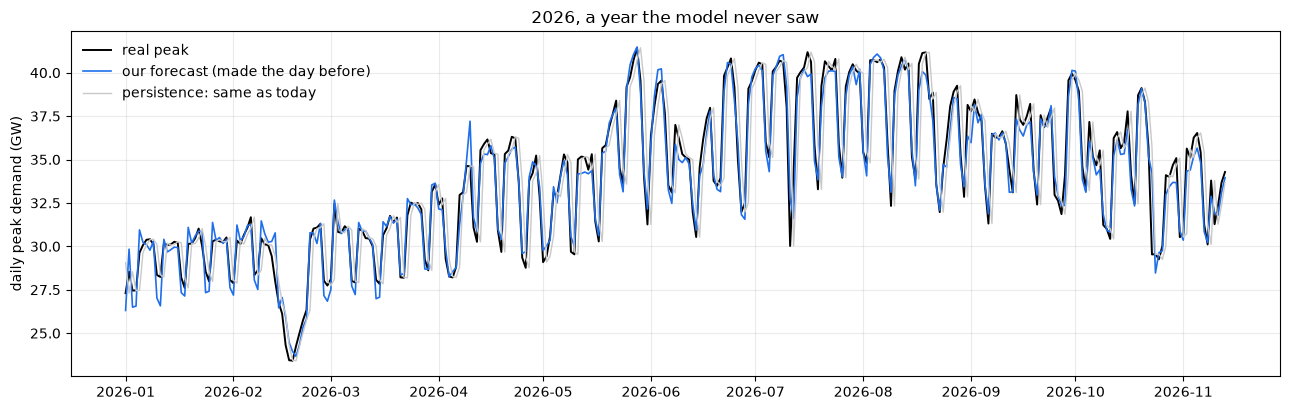

In [13]:
fig, ax = plt.subplots(figsize=(13, 4.2))
t = X.loc[TEST, "target_day"]
ax.plot(t, y[TEST] / 1000, color="black", lw=1.4, label="real peak")
ax.plot(t, pred[TEST] / 1000, color="#1f6feb", lw=1.2, label="our forecast (made the day before)")
ax.plot(t, X.loc[TEST, "load_today"] / 1000, color="#c9c9c9", lw=1, label="persistence: same as today")
ax.set_ylabel("daily peak demand (GW)"); ax.set_title("2026, a year the model never saw")
ax.legend(loc="upper left", frameon=False); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("results/forecast_2026.png", dpi=150); plt.show()

## 6. Where it fails
The biggest misses in 2026, with what we found out about each day.

In [14]:
KNOWN = {   # checked in the news; links in the README
    "2026-10-23": "Typhoon Champi: work and school called off across northern and central Taiwan",
    "2026-07-10": "Typhoon Bavi: work and school called off in 10 northern counties",
    "2026-07-11": "Typhoon Bavi: work and school called off in most counties",
    "2026-07-12": "day after Typhoon Bavi: the model trusted the low typhoon-day peak",
    "2026-02-13": "last workday before the 9-day Lunar New Year break",
    "2026-02-16": "Lunar New Year's Eve: demand fell further than on an average day of the break",
    "2026-09-28": "Teachers' Day, a public holiday again since 2025: demand stayed closer to a workday's",
}

def what_happened(idx):
    """Our note for a day: news we checked, plus checks the data can do by itself."""
    day = X.loc[idx, "target_day"]
    notes = [KNOWN[day.strftime("%Y-%m-%d")]] if day.strftime("%Y-%m-%d") in KNOWN else []
    dt = X.loc[idx, "tmax_fc"] - X.loc[idx, "tmax_obs"]
    if abs(dt) >= 2:
        notes.append(f"the weather forecast was {abs(dt):.1f} °C too {'hot' if dt > 0 else 'cold'}")
    if X.loc[idx, "t_off"] == 0 and X.loc[idx, "today_off"] == 1:
        n, d0 = 0, day - pd.Timedelta(days=1)
        while daily.loc[d0, "off"] == 1:
            n, d0 = n + 1, d0 - pd.Timedelta(days=1)
        if n >= 3:
            notes.append(f"first workday after a {n}-day break")
    return "; ".join(notes)

miss = pd.DataFrame({
    "day": X.loc[TEST, "target_day"].dt.strftime("%Y-%m-%d %a"),
    "real MW": y[TEST].round(0), "forecast MW": pred[TEST].round(0),
    "error %": ((pred[TEST] - y[TEST]) / y[TEST] * 100).round(1),
    "forecast max °C": X.loc[TEST, "tmax_fc"].round(1), "real max °C": X.loc[TEST, "tmax_obs"].round(1),
    "rain mm": X.loc[TEST, "rain_obs"].round(0),
})
miss["what happened"] = [what_happened(i) for i in miss.index]
worst = miss.reindex((pred[TEST] - y[TEST]).abs().sort_values(ascending=False).index).head(10)
worst

,day,real MW,forecast MW,error %,forecast max °C,real max °C,rain mm,what happened
2026-10-22,2026-10-23 Fri,29534.0,34228.0,15.9,26.3,26.9,42.0,Typhoon Champi: work and school called off across northern and central Taiwan
2026-02-12,2026-02-13 Fri,27982.0,30776.0,10.0,25.6,25.8,0.0,last workday before the 9-day Lunar New Year break
2026-07-10,2026-07-11 Sat,30023.0,32726.0,9.0,28.2,28.4,74.0,Typhoon Bavi: work and school called off in most counties
2026-07-11,2026-07-12 Sun,34277.0,31596.0,-7.8,32.4,33.4,8.0,day after Typhoon Bavi: the model trusted the low typhoon-day peak
2026-04-09,2026-04-10 Fri,34606.0,37207.0,7.5,32.6,29.4,0.0,the weather forecast was 3.2 °C too hot
2026-08-31,2026-09-01 Tue,37769.0,35971.0,-4.8,28.2,29.5,42.0,
2026-08-30,2026-08-31 Mon,38146.0,36353.0,-4.7,30.2,30.6,20.0,
2026-09-27,2026-09-28 Mon,34110.0,32352.0,-5.2,33.7,34.1,0.0,"Teachers' Day, a public holiday again since 2025: demand stayed closer to a workday's"
2026-04-06,2026-04-07 Tue,32957.0,31261.0,-5.1,25.5,26.0,14.0,first workday after a 4-day break
2026-01-10,2026-01-11 Sun,28237.0,26573.0,-5.9,20.0,20.1,0.0,


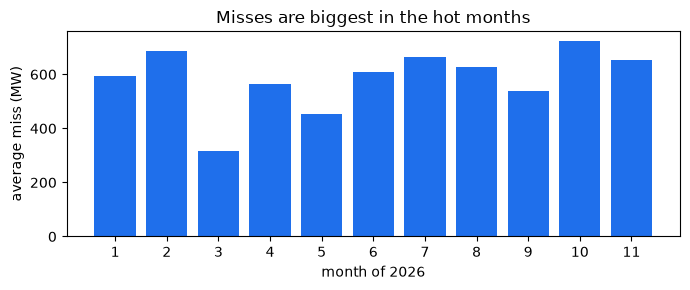

month of 2026,1,2,3,4,5,6,7,8,9,10,11
MAE (MW),594.0,686.0,315.0,566.0,455.0,607.0,663.0,627.0,538.0,723.0,654.0
"average error (MW, + = too high)",-179.0,112.0,-18.0,28.0,-72.0,-285.0,-304.0,-385.0,-260.0,-274.0,-537.0


In [15]:
e = (pred[TEST] - y[TEST])
by_month = pd.DataFrame({"MAE (MW)": e.abs().groupby(X.loc[TEST, "target_day"].dt.month).mean().round(0),
                         "average error (MW, + = too high)": e.groupby(X.loc[TEST, "target_day"].dt.month).mean().round(0)})
by_month.index.name = "month of 2026"
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(by_month.index, by_month["MAE (MW)"], color="#1f6feb"); ax.set_xticks(range(1, 12))
ax.set_xlabel("month of 2026"); ax.set_ylabel("average miss (MW)"); ax.set_title("Misses are biggest in the hot months")
plt.tight_layout(); plt.savefig("results/errors_by_month.png", dpi=150); plt.show()
by_month.T

**Why it fails there.**
* **Typhoon days off** are decided by each city the evening before, and they are not in the holiday calendar, so the
  model thinks it is a normal workday (16% too high for Typhoon Champi). The day after, it trusts the low typhoon-day
  peak and forecasts too low.
* **Around long breaks**: on the Friday before Lunar New Year many people take leave, so demand is lower than a normal
  Friday; on the first workday after a break, the model is pulled down by the holiday peak it saw "today".
* **When the weather forecast itself is wrong**: on 10 April the forecast was 3.2 °C too hot, and our forecast was 7.5%
  too high. The model can only be as good as the forecast it is fed.
* **New holidays**: Teachers' Day became a public holiday again in 2025. Government offices close, but demand stayed
  closer to a workday's, probably because many private companies stay open.
* **The hottest months**: the model is still a little low on average in June to November (see the chart), which is
  when the grid is most stretched. Section 10 adds one fix for the hot workdays.

## 7. Try it
Pick any 2026 day: the forecast made the evening before, what drove it, and what really happened.

In [16]:
GROUPS = {"weather": ["heat_above_24C", "heat_above_29C", "heat_above_29C_on_workday", "cold_below_17C", "humidity", "sunshine", "rain_log"],
          "day type": ["saturday_off", "sunday_off", "weekday_holiday", "makeup_workday", "lunar_new_year", "monday"],
          "recent demand": ["load_today", "load_same_day_last_week", "today_was_off"],
          "growth trend": ["years_since_2023"]}
TYPICAL = features(X[TRAIN_ALL], "obs", True).mean()      # an average 2023-25 day

def explain(day):
    row = X[X["target_day"] == pd.Timestamp(day)]
    f = features(row, "fc", True).iloc[0]
    typical = intercept + (coef * TYPICAL).sum()
    print(f"Forecast for {pd.Timestamp(day):%a %d %b %Y} (made the evening before)")
    print(f"  forecast max temperature {row['tmax_fc'].iloc[0]:.1f} °C, {'day off' if row['t_off'].iloc[0] else 'workday'} {row['t_holiday_name'].iloc[0]}")
    print(f"  an average 2023-25 day:   {typical:9,.0f} MW")
    for g, cols in GROUPS.items():
        print(f"  {g:24s} {(coef[cols] * (f[cols] - TYPICAL[cols])).sum():+9,.0f} MW")
    p, real = pred[row.index[0]], y[row.index[0]]
    print(f"  = forecast              {p:9,.0f} MW    real peak {real:,.0f} MW  (off by {(p - real) / real * 100:+.1f}%)")

explain("2026-08-03")
print()
explain("2026-10-23")

Forecast for Mon 03 Aug 2026 (made the evening before)
  forecast max temperature 34.3 °C, workday 
  an average 2023-25 day:      32,421 MW
  weather                     +3,710 MW
  day type                    +1,797 MW
  recent demand               +2,038 MW
  growth trend                  +507 MW
  = forecast                 40,474 MW    real peak 40,716 MW  (off by -0.6%)

Forecast for Fri 23 Oct 2026 (made the evening before)
  forecast max temperature 26.3 °C, workday 
  an average 2023-25 day:      32,421 MW
  weather                     -1,205 MW
  day type                      +826 MW
  recent demand               +1,625 MW
  growth trend                  +561 MW
  = forecast                 34,228 MW    real peak 29,534 MW  (off by +15.9%)


## 8. Question 1: can public data warn us about yellow-light days?
Taipower's light turns **yellow** when the reserve at the daily peak is under 10%. A warning the evening before would
help factories and schools plan. We test whether public data can give one.

In [17]:
tight_by_year = daily.assign(tight=daily["reserve_rate"] < 10).groupby(daily.index.year)["tight"].sum()
print("yellow-light days (reserve under 10%) per year:", tight_by_year.to_dict(), "  (none went below 6%, the orange light)")

def warn_features(X, load_fc):
    return pd.DataFrame({
        "rate_today": X["rate_today"], "lowest_rate_last_7_days": X["rate_min_7d"],
        "forecast_load_vs_supply_today": load_fc[X.index] / X["supply_today"],
        "day_off": X["t_off"], "sunshine": X["sunshine_fc"],
        "season_sin": np.sin(2 * np.pi * X["target_day"].dt.month / 12),
        "season_cos": np.cos(2 * np.pi * X["target_day"].dt.month / 12)})

yt = X["y_tight"]
# demand forecasts from a model that never saw 2025 (for validation) and from the final model (for the test)
load_fc_val = pd.Series(ridge().fit(features(X[TRAIN], "obs", True), y[TRAIN]).predict(features(X, "fc", True)), index=X.index)
warn = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=2000))
warn.fit(warn_features(X[TRAIN], load_fc_val), yt[TRAIN])
p_val = warn.predict_proba(warn_features(X[VAL], load_fc_val))[:, 1]
warn.fit(warn_features(X[TRAIN_ALL], pred), yt[TRAIN_ALL])
p_test = warn.predict_proba(warn_features(X[TEST], pred))[:, 1]
# pick the threshold with the best F1 on validation, then use it once on test
grid = np.linspace(0.05, 0.95, 91)
thr = grid[int(np.argmax([f1_score(yt[VAL], p_val > g, zero_division=0) for g in grid]))]
warned = p_test > thr
print(f"2026: {int(yt[TEST].sum())} yellow days. The model warned on {int(warned.sum())} of {int(TEST.sum())} days and caught "
      f"{int((warned & (yt[TEST] == 1)).sum())}; {100 * (1 - precision_score(yt[TEST], warned)):.0f}% of its warnings were false alarms.")
pd.DataFrame([
    {"warning method": "chance (share of yellow days)", "average precision": round(yt[TEST].mean(), 3), "precision": "", "recall": ""},
    {"warning method": "persistence: warn if today was yellow", "average precision": round(average_precision_score(yt[TEST], (X.loc[TEST, 'rate_today'] < 10).astype(float)), 3),
     "precision": round(precision_score(yt[TEST], X.loc[TEST, "rate_today"] < 10), 2), "recall": round(recall_score(yt[TEST], X.loc[TEST, "rate_today"] < 10), 2)},
    {"warning method": f"logistic regression (threshold {thr:.2f} from 2025)", "average precision": round(average_precision_score(yt[TEST], p_test), 3),
     "precision": round(precision_score(yt[TEST], p_test > thr, zero_division=0), 2), "recall": round(recall_score(yt[TEST], p_test > thr), 2)},
]).set_index("warning method")

yellow-light days (reserve under 10%) per year: {2023: 8, 2024: 19, 2025: 23, 2026: 12}   (none went below 6%, the orange light)


2026: 12 yellow days. The model warned on 180 of 317 days and caught 10; 94% of its warnings were false alarms.


,average precision,precision,recall
warning method,,,
chance (share of yellow days),0.038,,
persistence: warn if today was yellow,0.042,0.08,0.08
logistic regression (threshold 0.40 from 2025),0.093,0.06,0.83


,peak demand vs month's median,supply vs month's median
yellow days,-3.3%,-8.8%
other days,0.0%,0.1%


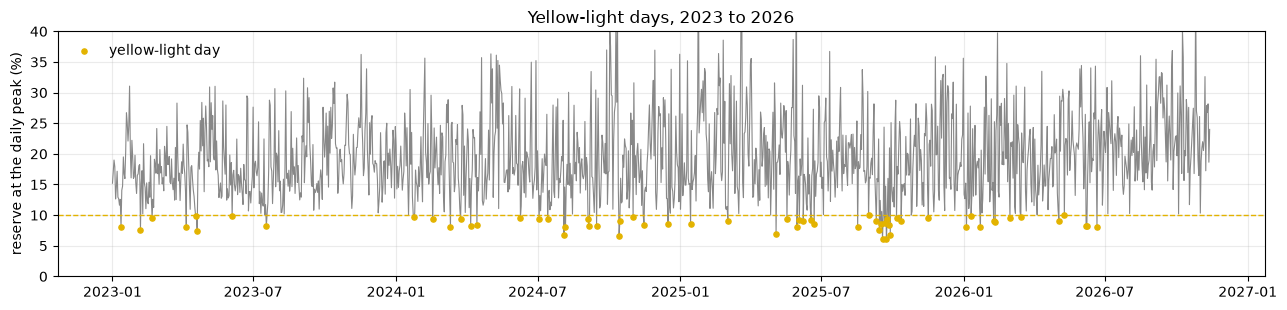

In [18]:
# Why: on yellow days, was demand unusual, or supply?
month = daily.index.to_period("M")
load_vs_month = daily["load"] / daily.groupby(month)["load"].transform("median") - 1
supply_vs_month = daily["supply"] / daily.groupby(month)["supply"].transform("median") - 1
tight = daily["reserve_rate"] < 10
cmp = pd.DataFrame({"peak demand vs month's median": [load_vs_month[tight].median(), load_vs_month[~tight].median()],
                    "supply vs month's median": [supply_vs_month[tight].median(), supply_vs_month[~tight].median()]},
                   index=["yellow days", "other days"])
display((cmp * 100).round(1).astype(str) + "%")
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.plot(daily.index, daily["reserve_rate"], color="#888", lw=.8)
ax.scatter(daily.index[tight], daily.loc[tight, "reserve_rate"], color="#e3b300", s=14, zorder=3, label="yellow-light day")
ax.axhline(10, color="#e3b300", lw=1, ls="--"); ax.set_ylim(0, 40); ax.set_ylabel("reserve at the daily peak (%)")
ax.legend(frameon=False, loc="upper left"); ax.set_title("Yellow-light days, 2023 to 2026"); ax.grid(alpha=.25)
plt.tight_layout(); plt.savefig("results/yellow_days.png", dpi=150); plt.show()

**Answer: no, not from public data.** The warning model only "catches" yellow days by warning on most days, so
almost all of its warnings are false alarms, and nobody could plan with that. The reason shows in the table above: on
yellow days, demand was actually a little **below** normal for the month, but the **supply** was well below normal.
Yellow days come from power plants that are off for repairs or breakdowns, which the public cannot see the evening
before. That is useful to know: a weather-based app can't warn you about a yellow day, however good its demand
forecast is. Taipower's maintenance plans would be needed, so we did **not** put a yellow-light forecast in the demo.

## 9. Question 2: is demand growing faster than the weather explains?
We fit a model with **only** weather and day type (no recent demand, no trend) on 2023, then ask how far each later
year sits above it. If 2026 had 2023's weather, how much more power would it still need?

In [19]:
W_ONLY = ["heat_above_24C", "heat_above_29C", "heat_above_29C_on_workday", "cold_below_17C", "humidity", "sunshine", "rain_log",
          "saturday_off", "sunday_off", "weekday_holiday", "makeup_workday", "lunar_new_year", "monday"]
fw = features(X, "obs", True)[W_ONLY]
y2023 = year == 2023
wonly = ridge().fit(fw[y2023], y[y2023])
gap = y - wonly.predict(fw)
growth = gap.groupby(year).agg(["mean", "std", "count"])
growth["95% range ±"] = 1.96 * growth["std"] / np.sqrt(growth["count"])
growth = growth[["mean", "95% range ±"]].round(0)
growth.columns = ["extra demand vs 2023 (MW)", "95% range ±"]
display(growth)
unit = full["核三#2(萬瓩)"].max() * 10
print(f"2026 needs about {growth.iloc[-1, 0]:,.0f} MW more than 2023 at the same weather: "
      f"{growth.iloc[-1, 0] / unit:.1f} times one Maanshan nuclear unit ({unit:,.0f} MW in Taipower's table)")

,extra demand vs 2023 (MW),95% range ±
target_day,,
2023,-0.0,95.0
2024,661.0,139.0
2025,668.0,110.0
2026,1536.0,120.0


2026 needs about 1,536 MW more than 2023 at the same weather: 1.6 times one Maanshan nuclear unit (947 MW in Taipower's table)


In [20]:
# Which users? Taipower's full table splits daily electricity into industry and homes+shops (Jan-Aug, after the typo fix)
u = usage.loc[usage.index.month <= 8]
by = u.groupby(u.index.year).sum()
by.loc["growth 2025->2026 (%)"] = ((by.loc[2026] / by.loc[2025] - 1) * 100)
by.round(1)

,industry_gwh,homes_shops_gwh
date,,
2025,89722.2,66399.6
2026,88781.9,67468.9
growth 2025->2026 (%),-1.0,1.6


**Answer: the peaks are growing, but there is a puzzle.** At the same weather and day type, the daily peak was about
0.7 GW higher in 2024 and 2025 than in 2023, and about 1.5 GW higher in 2026. That is more than one and a half
Maanshan nuclear units, and it is why the model needs its growth trend and recent-demand features.

But Taipower's own daily **energy** totals (the table above) barely changed from 2025 to 2026, for industry and for
homes and shops. So in 2026 the peak grew while total use did not. Two explanations fit: the extra demand is packed
into the peak hours (for example more air conditioning on hot afternoons), or Taipower now counts the peak a little
differently (for example with more rooftop solar included). Public data can't tell these apart, so we report it as an
open question, not as a finding about chip factories or AI data centres.

## 10. One improvement: heat costs more on workdays
Looking at the misses, the model was too low on hot **workdays**: offices, schools and factories all run their air
conditioning at once. We added one feature, degrees above 29 °C **on a workday**, and chose it on the 2025 validation
year only.

In [21]:
m0 = ridge().fit(features(X[TRAIN], "obs"), y[TRAIN]); m1 = ridge().fit(features(X[TRAIN], "obs", True), y[TRAIN])
summer = X["target_day"].dt.month.isin([6, 7, 8])
rows = []
for name, mb, mf in [("before", basic, False), ("after", final, True)]:
    p_test_ = pd.Series(mb.predict(features(X, "fc", mf)), index=X.index)
    p_val_ = pd.Series((m0 if not mf else m1).predict(features(X, "fc", mf)), index=X.index)
    rows.append({"model": name,
                 "validation 2025 MAE (MW)": round(mean_absolute_error(y[VAL], p_val_[VAL])),
                 "test 2026 MAE (MW)": round(mean_absolute_error(y[TEST], p_test_[TEST])),
                 "test 2026, Jun-Aug only (MW)": round(mean_absolute_error(y[TEST & summer], p_test_[TEST & summer]))})
display(pd.DataFrame(rows).set_index("model"))
print(f"cost: none in complexity that matters (one more weight); each °C above 29 on a workday now adds "
      f"{coef['heat_above_24C'] + coef['heat_above_29C'] + coef['heat_above_29C_on_workday']:,.0f} MW, "
      f"vs {coef['heat_above_24C'] + coef['heat_above_29C']:,.0f} MW on a day off")

,validation 2025 MAE (MW),test 2026 MAE (MW),"test 2026, Jun-Aug only (MW)"
model,,,
before,701,613,649
after,646,580,633


cost: none in complexity that matters (one more weight); each °C above 29 on a workday now adds 719 MW, vs 307 MW on a day off


## 11. Save the model for the web demo
The demo page runs this same model in the browser: it is just 17 weights and an intercept, so the page needs no server.
We also save every 2026 forecast so the page can replay the test year.

In [22]:
import joblib
os.makedirs("models", exist_ok=True)
joblib.dump(final, "models/power_weather_ridge.joblib")

fT = features(X[TEST], "fc", True)
# each city's own day-ahead forecast of the max temperature (the map in the demo shows these)
CITY_NAMES = list(CITIES)
city_tmax = {}
for name, loc in zip(CITY_NAMES, fc_json):
    h = pd.DataFrame(loc["hourly"]); h.index = pd.to_datetime(h.pop("time"))
    city_tmax[name] = h["temperature_2m_previous_day1"].resample("D").max(min_count=20)
city_tmax = pd.DataFrame(city_tmax)
def city_row(day):
    return [None if pd.isna(v) else round(float(v), 1) for v in city_tmax.loc[day, CITY_NAMES]]
days = []
for i, idx in enumerate(X.index[TEST]):
    r, f = X.loc[idx], fT.loc[idx]
    contrib = {g: round(float((coef[c] * (f[c] - TYPICAL[c])).sum())) for g, c in GROUPS.items()}
    days.append({"date": r["target_day"].strftime("%Y-%m-%d"), "dow": int(r["t_dow"]), "off": int(r["t_off"]),
                 "holiday": r["t_holiday_name"], "note": what_happened(idx),
                 "tmax_fc": round(float(r["tmax_fc"]), 4), "tmean_fc": round(float(r["tmean_fc"]), 4),
                 "humidity_fc": round(float(r["humidity_fc"]), 4), "sunshine_fc": round(float(r["sunshine_fc"]), 4),
                 "rain_fc": round(float(r["rain_fc"]), 4), "load_today": round(float(r["load_today"]), 2),
                 "load_last_week": round(float(r["load_last_week"]), 2), "today_off": int(r["today_off"]),
                 "years": round(float(r["years"]), 6), "lny": int(r["t_lunar_new_year"]),
                 "actual": round(float(y[idx])), "pred": round(float(pred[idx])), "persistence": round(float(r["load_today"])),
                 "reserve_rate": round(float(r["y_rate"]), 2), "contrib": contrib, "city_tmax": city_row(r["target_day"])})
# the newest forecast we can make: for the day after the last day of data (no real value yet)
today = daily.index.max(); tom = today + pd.Timedelta(days=1)
L = pd.DataFrame({"target_day": [tom], "t_dow": [tom.dayofweek], "t_off": [int(cal["是否放假"].get(tom) == 2)],
                  "t_lunar_new_year": [0], "t_holiday_name": [str(cal["備註"].get(tom) if pd.notna(cal["備註"].get(tom)) else "")],
                  "load_today": [daily.loc[today, "load"]], "load_last_week": [daily.loc[today - pd.Timedelta(days=6), "load"]],
                  "today_off": [daily.loc[today, "off"]], "years": [(tom - pd.Timestamp("2023-01-01")).days / 365.25]}, index=[today])
for k in ["tmax", "tmean", "humidity", "rain", "sunshine"]:
    L[k + "_fc"] = fc.loc[tom, k]
fL = features(L, "fc", True).iloc[0]
latest = {"date": tom.strftime("%Y-%m-%d"), "dow": int(tom.dayofweek), "off": int(L["t_off"].iloc[0]), "holiday": L["t_holiday_name"].iloc[0],
          "tmax_fc": round(float(L["tmax_fc"].iloc[0]), 4), "tmean_fc": round(float(L["tmean_fc"].iloc[0]), 4),
          "humidity_fc": round(float(L["humidity_fc"].iloc[0]), 4), "sunshine_fc": round(float(L["sunshine_fc"].iloc[0]), 4),
          "rain_fc": round(float(L["rain_fc"].iloc[0]), 4), "load_today": round(float(L["load_today"].iloc[0]), 2),
          "load_last_week": round(float(L["load_last_week"].iloc[0]), 2), "today_off": int(L["today_off"].iloc[0]),
          "years": round(float(L["years"].iloc[0]), 6), "lny": 0, "pred": round(float(final.predict(features(L, "fc", True))[0])),
          "contrib": {g: round(float((coef[c] * (fL[c] - TYPICAL[c])).sum())) for g, c in GROUPS.items()},
          "city_tmax": city_row(tom)}
print(f"newest forecast: {latest['date']} -> {latest['pred']:,} MW (made with data up to {today:%Y-%m-%d})")

web = {
    "title": "Power Weather Taiwan",
    "latest": latest,
    "cities": [{"name": n, "lat": CITIES[n][0], "lon": CITIES[n][1], "weight": CITIES[n][2]} for n in CITY_NAMES],
    "yellow_2026": {"days": int(yt[TEST].sum()), "warned": int(warned.sum()), "caught": int((warned & (yt[TEST] == 1)).sum()),
                    "test_days": int(TEST.sum()), "false_alarm_pct": round(100 * (1 - precision_score(yt[TEST], warned)))},
    "yellow_cause": {"demand_pct": round(float(cmp.iloc[0, 0] * 100), 1), "supply_pct": round(float(cmp.iloc[0, 1] * 100), 1)},
    "made": time.strftime("%Y-%m-%d"),
    "features": list(names), "coef": [round(float(c), 6) for c in coef], "intercept": round(float(intercept), 3),
    "typical": {n: round(float(TYPICAL[n]), 6) for n in names}, "groups": GROUPS,
    "typical_load": round(float(intercept + (coef * TYPICAL).sum())),
    "scores": table.set_index("method")["MAE (%)"].to_dict(),
    "scores_mw": table.set_index("method")["MAE (MW)"].to_dict(),
    "growth": {int(k): int(v) for k, v in growth.iloc[:, 0].items()},
    "maanshan_mw": round(float(unit)),
    "yellow_days": {int(k): int(v) for k, v in tight_by_year.items()},
    "record_2026": {"date": X.loc[y[TEST].idxmax(), "target_day"].strftime("%Y-%m-%d"), "mw": round(float(y[TEST].max()))},
    "days": days,
}
with open("docs/model.json", "w", encoding="utf-8") as fh:
    json.dump(web, fh, ensure_ascii=False, separators=(",", ":"))
print(f"saved models/power_weather_ridge.joblib and docs/model.json ({os.path.getsize('docs/model.json') / 1e3:.0f} kB, {len(days)} days)")

newest forecast: 2026-11-14 -> 30,255 MW (made with data up to 2026-11-13)
saved models/power_weather_ridge.joblib and docs/model.json (146 kB, 317 days)


C:\Users\USER\AppData\Local\Temp\ipykernel_58216\2921507852.py:30: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  L = pd.DataFrame({"target_day": [tom], "t_dow": [tom.dayofweek], "t_off": [int(cal["是否放假"].get(tom) == 2)],
C:\Users\USER\AppData\Local\Temp\ipykernel_58216\2921507852.py:37: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  latest = {"date": tom.strftime("%Y-%m-%d"), "dow": int(tom.dayofweek), "off": int(L["t_off"].iloc[0]), "holiday": L["t_holiday_name"].iloc[0],
